# 00 — Data preparation and dataset exploration
**Group 2 — Emotion recognition (FER2013 vs KDEF)**

Run this notebook **after** the two kit notebooks `z_load_split_fer2013.ipynb` and
`z_load_kdef_student.ipynb` (they write `data/fer2013_{train,validation,test}.csv` and
`data/kdef_preprocessed.pkl`). This notebook:

1. converts the FER2013 splits to uint8 image arrays and computes their dlib landmarks once;
2. preprocesses the frontal KDEF images into the FER format (Haar crop → gray → 48×48), in
   several variants needed later: crop margins 0 / 0.1 / 0.2 / 0.3, RGB, eye-aligned;
3. checks our preprocessing against the kit output;
4. explores the characteristics of both datasets (class balance, intensity, framing,
   blank images, duplicates, landmark quality) — the evidence for the report's dataset section.

Everything is cached in `data/cache/` and reused by notebooks 01–05.

In [13]:
# Common setup + evaluation helpers (identical in every notebook of the project)
import os, sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             confusion_matrix, classification_report)
from sklearn.model_selection import StratifiedShuffleSplit

sys.path.insert(0, str(Path.cwd()))
try:
    from src import features as F
except ImportError:  # fuzzy environment (no OpenCV/dlib): only cached features are used there
    from types import SimpleNamespace
    F = SimpleNamespace(EMOTIONS=["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"],
                        CACHE_DIR=Path("data") / "cache")

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# SMOKE=1 (environment variable) runs everything on small subsets with reduced grids, to
# check the notebook end-to-end in minutes. The delivered results use SMOKE=0 (default).
SMOKE = os.environ.get("SMOKE", "0") == "1"
SEED = 42
N_JOBS = -1
EMO = F.EMOTIONS
RESULTS_DIR, FIG_DIR, MODEL_DIR = Path("results"), Path("figures"), Path("models")
for d in (RESULTS_DIR, FIG_DIR, MODEL_DIR, F.CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight"})
print(f"SMOKE={SMOKE}")


def metrics(y_true, y_pred):
    return {"acc": accuracy_score(y_true, y_pred),
            "bal_acc": balanced_accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro", labels=range(7), zero_division=0)}


def per_class_f1(y_true, y_pred):
    return pd.Series(f1_score(y_true, y_pred, average=None, labels=range(7), zero_division=0), index=EMO)


_RESULTS = {}


def reset_results(task):
    """Start a fresh results/<task>.csv for this run of the notebook."""
    _RESULTS[task] = []
    (RESULTS_DIR / f"{task}.csv").unlink(missing_ok=True)


def log_result(task, y_true, y_pred, **info):
    """Append one evaluation row (fixed schema) to results/<task>.csv and return it."""
    row = {**info, **{k: round(v, 4) for k, v in metrics(y_true, y_pred).items()}, "n": len(y_true)}
    _RESULTS.setdefault(task, []).append(row)
    pd.DataFrame(_RESULTS[task]).to_csv(RESULTS_DIR / f"{task}.csv", index=False)
    return row


def fixed_table(df, index, columns, value, index_order, column_order):
    """Pivot to a table with a FIXED row/column layout (same x and y in every task)."""
    t = df.pivot_table(index=index, columns=columns, values=value, aggfunc="first")
    return t.reindex(index=index_order, columns=column_order)


def save_table(df, name, float_format="%.3f"):
    """Save a table as CSV and as a LaTeX tabular (pasted into report/*.md)."""
    df.to_csv(RESULTS_DIR / f"{name}.csv")
    with open(RESULTS_DIR / f"{name}.tex", "w", encoding="utf-8") as f:
        f.write(df.to_latex(float_format=float_format, na_rep="--"))
    return df


def plot_cm(y_true, y_pred, title="", ax=None, normalize=True):
    cm = confusion_matrix(y_true, y_pred, labels=range(7), normalize="true" if normalize else None)
    ax = ax or plt.subplots(figsize=(4.2, 3.6))[1]
    sns.heatmap(cm, annot=True, fmt=".2f" if normalize else "d", cmap="Blues", cbar=False,
                xticklabels=[e[:3] for e in EMO], yticklabels=[e[:3] for e in EMO], ax=ax,
                vmin=0, vmax=1 if normalize else None, annot_kws={"size": 7})
    ax.set_title(title, fontsize=9); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    return ax


def plot_cm_grid(items, fname, ncols=4):
    """items: list of (title, y_true, y_pred). Saved in figures/ for the report appendix."""
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.7 * nrows), squeeze=False)
    for ax, (title, yt, yp) in zip(axes.ravel(), items):
        plot_cm(yt, yp, title, ax=ax)
    for ax in axes.ravel()[len(items):]:
        ax.axis("off")
    fig.tight_layout(); fig.savefig(FIG_DIR / fname); plt.show()


def stratified_subset(y, n, seed=SEED):
    """Indices of a stratified random subset of size n (all indices if n >= len(y))."""
    if n is None or n >= len(y):
        return np.arange(len(y))
    sss = StratifiedShuffleSplit(n_splits=1, train_size=n, random_state=seed)
    return np.sort(next(sss.split(np.zeros(len(y)), y))[0])


def scores(model, X):
    """Class scores for confidence analyses (predict_proba, else softmax(decision_function))."""
    if hasattr(model, "predict_proba"):
        try:
            return model.predict_proba(X)
        except AttributeError:
            pass
    d = model.decision_function(X)
    e = np.exp(d - d.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def save_bundle(name, model, spec, **extra):
    """Persist a FITTED model together with the feature spec needed to use it (demo, other tasks)."""
    bundle = {"model": model, "spec": spec, "labels": EMO, **extra}
    joblib.dump(bundle, MODEL_DIR / f"{name}.pkl", compress=3)
    print(f"saved models/{name}.pkl")


def show_images(imgs, titles=None, ncols=8, size=1.5, fname=None, suptitle=None, cmap="gray"):
    nrows = int(np.ceil(len(imgs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * 1.15 * nrows), squeeze=False)
    for i, ax in enumerate(axes.ravel()):
        ax.axis("off")
        if i < len(imgs):
            ax.imshow(imgs[i], cmap=None if imgs[i].ndim == 3 else cmap, vmin=0, vmax=255)
            if titles is not None:
                ax.set_title(titles[i], fontsize=7)
    if suptitle:
        fig.suptitle(suptitle, fontsize=10)
    fig.tight_layout()
    if fname:
        fig.savefig(FIG_DIR / fname)
    plt.show()

SMOKE=False


## 1. FER2013 → image arrays + landmarks

In [14]:
fer = {}
for split, short in [("train", "train"), ("validation", "val"), ("test", "test")]:
    X, y = F.load_fer_split(split)
    fer[f"X_{short}"], fer[f"y_{short}"] = X, y
    print(f"{split:10s} {X.shape}  classes: {np.bincount(y, minlength=7)}")
assert len(fer["y_test"]) == 3589 and len(fer["y_val"]) == 3589 and len(fer["y_train"]) == 28709
np.savez_compressed(F.CACHE_DIR / "fer_gray.npz", **fer)

t = time.time()
for s in ("train", "val", "test"):
    F.cached(f"fer_gray_{s}_pts", lambda: F.extract_landmarks(fer[f"X_{s}"]), force=True)
print(f"landmarks done in {time.time() - t:.0f}s")

train      (28709, 48, 48)  classes: [3995  436 4097 7215 4830 3171 4965]
validation (3589, 48, 48)  classes: [467  56 496 895 653 415 607]
test       (3589, 48, 48)  classes: [491  55 528 879 594 416 626]
landmarks done in 28s


## 2. KDEF (frontal) → FER format
The official subject split (`auxFiles/kdef_subject_split.pkl`, corrected version: series A and B
of the same person are one subject) gives 56 training and 14 test subjects. Only the frontal
pose (`S`) is used. Our `preprocess_kdef_image` extends the kit's function (same Haar detector,
same parameters) with a configurable margin, an RGB output and an optional eye alignment.

In [15]:
kdef_train_df, kdef_test_df = F.load_kdef_frontal_split()
print(len(kdef_train_df), "train images /", kdef_train_df.subject.nunique(), "subjects")
print(len(kdef_test_df), "test images /", kdef_test_df.subject.nunique(), "subjects")
assert len(kdef_train_df) == 784 and len(kdef_test_df) == 196

KDEF_VARIANTS = {
    "m0.0_gray": dict(margin=0.0), "m0.1_gray": dict(margin=0.1),
    "m0.2_gray": dict(margin=0.2), "m0.3_gray": dict(margin=0.3),
    "m0.2_rgb": dict(margin=0.2, color="rgb"),
    "m0.0_gray_aligned": dict(margin=0.0, align=True), "m0.1_gray_aligned": dict(margin=0.1, align=True),
    "m0.2_gray_aligned": dict(margin=0.2, align=True), "m0.3_gray_aligned": dict(margin=0.3, align=True),
}
detect_fail = {}
for name, kw in KDEF_VARIANTS.items():
    out = {}
    for split, df in [("train", kdef_train_df), ("test", kdef_test_df)]:
        X, ok = F.preprocess_kdef_batch(df.path.tolist(), **kw)
        detect_fail[(name, split)] = int((~ok).sum())
        out[f"X_{split}"], out[f"y_{split}"] = X[ok], df.label.to_numpy()[ok]
        out[f"subj_{split}"], out[f"path_{split}"] = df.subject.to_numpy()[ok], df.path.to_numpy()[ok]
    np.savez_compressed(F.CACHE_DIR / f"kdef_{name}.npz", **out)
    print(f"{name:20s} train {out['X_train'].shape} test {out['X_test'].shape}")
print("face detection failures:", {k: v for k, v in detect_fail.items() if v} or "none")

784 train images / 56 subjects
196 test images / 14 subjects
m0.0_gray            train (784, 48, 48) test (196, 48, 48)
m0.1_gray            train (784, 48, 48) test (196, 48, 48)
m0.2_gray            train (784, 48, 48) test (196, 48, 48)
m0.3_gray            train (784, 48, 48) test (196, 48, 48)
m0.2_rgb             train (784, 48, 48, 3) test (196, 48, 48, 3)
m0.0_gray_aligned    train (784, 48, 48) test (196, 48, 48)
m0.1_gray_aligned    train (784, 48, 48) test (196, 48, 48)
m0.2_gray_aligned    train (784, 48, 48) test (196, 48, 48)
m0.3_gray_aligned    train (784, 48, 48) test (196, 48, 48)
face detection failures: none


**Sanity check against the kit:** our default variant (margin 0.2, gray) must reproduce
`data/kdef_preprocessed.pkl` (the kit stores float images in [0,1]; we keep uint8).

In [16]:
import pickle
kit = pickle.load(open("data/kdef_preprocessed.pkl", "rb"))
ours = dict(np.load(F.CACHE_DIR / "kdef_m0.2_gray.npz", allow_pickle=True))
diff = np.abs(ours["X_train"].astype(np.float32) - np.asarray(kit["X_train"]) * 255).max()
print("max |ours - kit| (gray levels):", diff)
assert ours["X_train"].shape == np.asarray(kit["X_train"]).shape and diff <= 1.0
assert [F.KDEF_TO_FER[e] for e in kit["y_train"]] == ours["y_train"].tolist()

max |ours - kit| (gray levels): 0.0


In [17]:
for name in KDEF_VARIANTS:
    if name.endswith("rgb"):
        continue
    d = dict(np.load(F.CACHE_DIR / f"kdef_{name}.npz", allow_pickle=True))
    for s in ("train", "test"):
        F.cached(f"kdef_{name}_{s}_pts", lambda: F.extract_landmarks(d[f"X_{s}"], margin=KDEF_VARIANTS[name]["margin"]), force=True)

# FER eye-aligned copy (used by the cross-dataset alignment experiment)
fer_aligned = {}
for s in ("train", "val", "test"):
    pts = np.load(F.CACHE_DIR / f"fer_gray_{s}_pts.npy")
    fer_aligned[f"X_{s}"] = F.align_images_by_eyes(fer[f"X_{s}"], pts)
    fer_aligned[f"y_{s}"] = fer[f"y_{s}"]
np.savez_compressed(F.CACHE_DIR / "fer_aligned.npz", **fer_aligned)
for s in ("train", "val", "test"):
    F.cached(f"fer_aligned_{s}_pts", lambda: F.extract_landmarks(fer_aligned[f"X_{s}"]), force=True)

## 3. Dataset exploration
### 3.1 Class distributions

,FER train,FER val (PublicTest),FER test (PrivateTest),KDEF train,KDEF test
Angry,3995,467,491,112,28
Disgust,436,56,55,112,28
Fear,4097,496,528,112,28
Happy,7215,895,879,112,28
Sad,4830,653,594,112,28
Surprise,3171,415,416,112,28
Neutral,4965,607,626,112,28


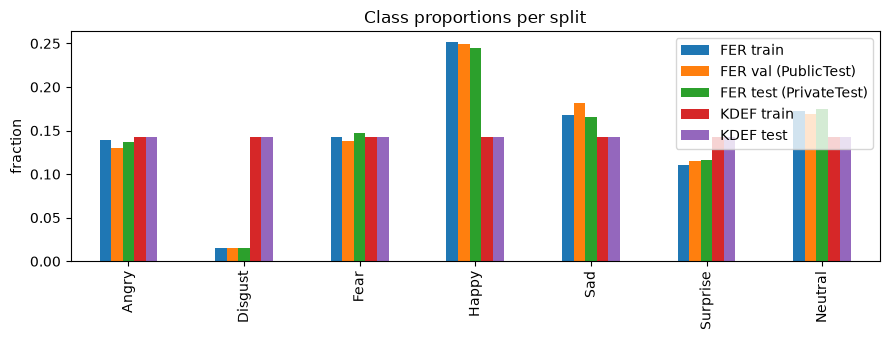

FER imbalance ratio (Happy / Disgust): 16.5


In [18]:
kd = dict(np.load(F.CACHE_DIR / "kdef_m0.2_gray.npz", allow_pickle=True))
dist = pd.DataFrame({
    "FER train": np.bincount(fer["y_train"], minlength=7),
    "FER val (PublicTest)": np.bincount(fer["y_val"], minlength=7),
    "FER test (PrivateTest)": np.bincount(fer["y_test"], minlength=7),
    "KDEF train": np.bincount(kd["y_train"], minlength=7),
    "KDEF test": np.bincount(kd["y_test"], minlength=7),
}, index=EMO)
save_table(dist, "data_class_distribution", float_format="%d")
display(dist)
(dist / dist.sum()).plot.bar(figsize=(9, 3.5), title="Class proportions per split")
plt.ylabel("fraction"); plt.tight_layout(); plt.savefig(FIG_DIR / "data_class_distribution.png"); plt.show()
print("FER imbalance ratio (Happy / Disgust):", round(dist.loc["Happy", "FER train"] / dist.loc["Disgust", "FER train"], 1))

### 3.2 Samples: one row per emotion, FER (left) vs KDEF (right)

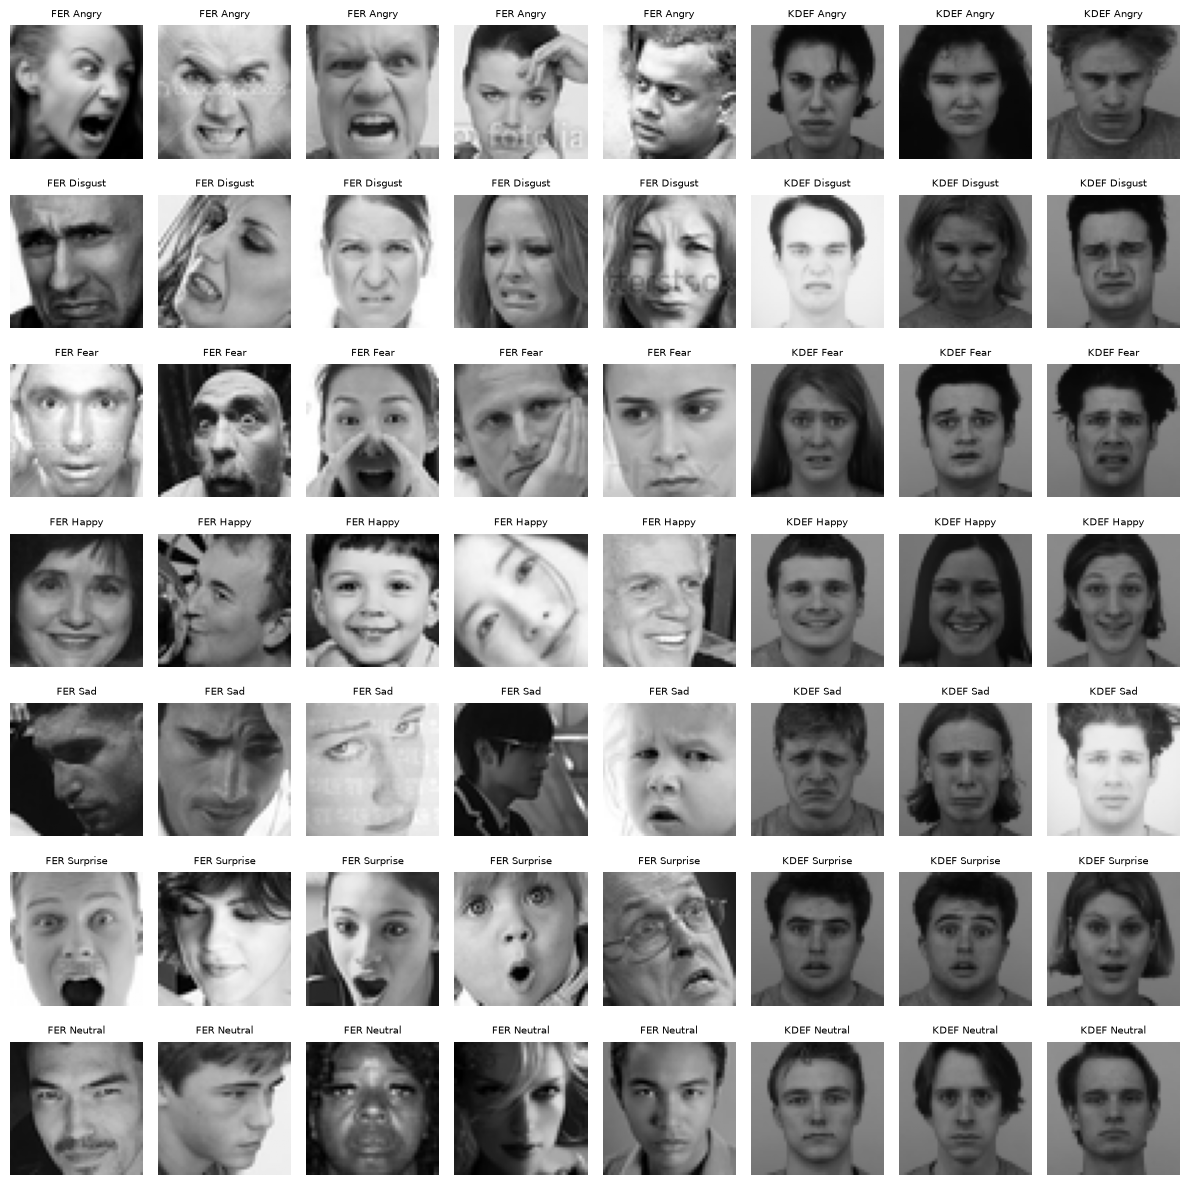

In [19]:
rng = np.random.default_rng(SEED)
imgs, titles = [], []
for c in range(7):
    for i in rng.choice(np.where(fer["y_train"] == c)[0], 5, replace=False):
        imgs.append(fer["X_train"][i]); titles.append(f"FER {EMO[c]}")
    for i in rng.choice(np.where(kd["y_train"] == c)[0], 3, replace=False):
        imgs.append(kd["X_train"][i]); titles.append(f"KDEF {EMO[c]}")
show_images(imgs, titles, ncols=8, fname="data_samples.png")

### 3.3 Mean faces and intensity statistics
The average face shows the framing difference (factor *i* of the domain shift); the intensity
histograms show the acquisition difference (lighting/contrast, factor *iii*).

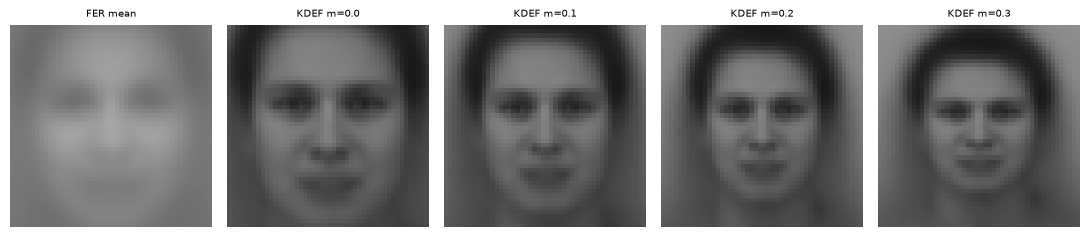

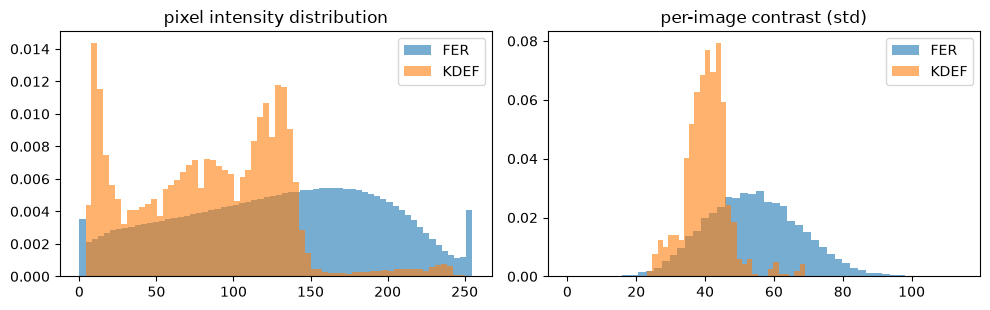

,mean intensity,std of per-image mean (lighting variability),mean per-image contrast
FER train,129.47,33.51,54.03
KDEF train,83.76,26.26,40.50


In [20]:
mean_faces = [fer["X_train"].mean(axis=0)] + [np.load(F.CACHE_DIR / f"kdef_{m}_gray.npz")["X_train"].mean(axis=0)
                                         for m in ("m0.0", "m0.1", "m0.2", "m0.3")]
show_images(mean_faces, ["FER mean", "KDEF m=0.0", "KDEF m=0.1", "KDEF m=0.2", "KDEF m=0.3"],
            ncols=5, size=2.2, fname="data_mean_faces.png")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(fer["X_train"].ravel(), bins=64, density=True, alpha=0.6, label="FER")
axes[0].hist(kd["X_train"].ravel(), bins=64, density=True, alpha=0.6, label="KDEF")
axes[0].set_title("pixel intensity distribution"); axes[0].legend()
axes[1].hist(fer["X_train"].reshape(len(fer["X_train"]), -1).std(1), bins=50, density=True, alpha=0.6, label="FER")
axes[1].hist(kd["X_train"].reshape(len(kd["X_train"]), -1).std(1), bins=30, density=True, alpha=0.6, label="KDEF")
axes[1].set_title("per-image contrast (std)"); axes[1].legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "data_intensity.png"); plt.show()

stats = pd.DataFrame({
    "mean intensity": [fer["X_train"].mean(), kd["X_train"].mean()],
    "std of per-image mean (lighting variability)": [fer["X_train"].mean((1, 2)).std(), kd["X_train"].mean((1, 2)).std()],
    "mean per-image contrast": [fer["X_train"].std((1, 2)).mean(), kd["X_train"].std((1, 2)).mean()],
}, index=["FER train", "KDEF train"])
save_table(stats.round(2), "data_intensity_stats", float_format="%.2f"); display(stats.round(2))

### 3.4 FER quality issues: blank images and duplicates
FER2013 was collected automatically with web image search, so it contains near-blank images
and (near-)duplicates, also *across* the official splits. These affect both training and
the reliability of the evaluation. (KDEF has none of these problems.)

near-blank images (pixel std < 3): {'train': 12, 'val': 1, 'test': 0}


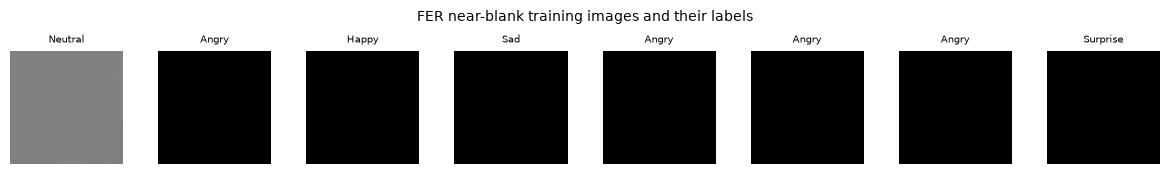

,count
within train,1347
within val,26
within test,20
test images also in train,308
val images also in train,299
train duplicate groups with conflicting labels,59


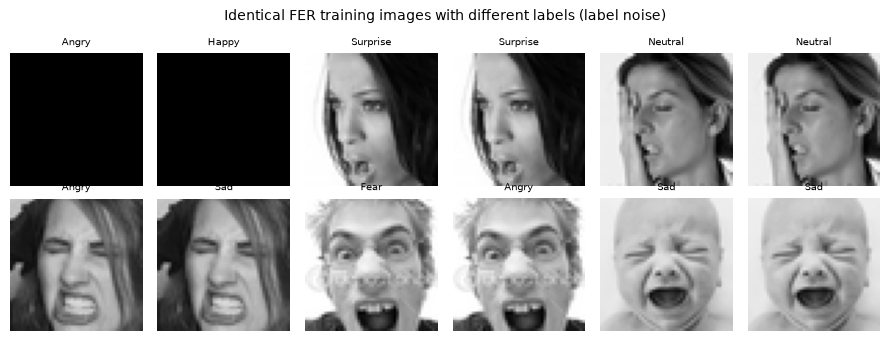

In [21]:
blank = {s: np.where(fer[f"X_{s}"].reshape(len(fer[f"X_{s}"]), -1).std(1) < 3)[0] for s in ("train", "val", "test")}
print("near-blank images (pixel std < 3):", {s: len(v) for s, v in blank.items()})
if len(blank["train"]):
    show_images(fer["X_train"][blank["train"][:8]], [EMO[fer["y_train"][i]] for i in blank["train"][:8]],
                fname="data_fer_blank.png", suptitle="FER near-blank training images and their labels")

hashes = {s: F.dhash(fer[f"X_{s}"]) for s in ("train", "val", "test")}
dup = {
    "within train": len(hashes["train"]) - len(np.unique(hashes["train"])),
    "within val": len(hashes["val"]) - len(np.unique(hashes["val"])),
    "within test": len(hashes["test"]) - len(np.unique(hashes["test"])),
    "test images also in train": int(np.isin(hashes["test"], hashes["train"]).sum()),
    "val images also in train": int(np.isin(hashes["val"], hashes["train"]).sum()),
}
# label consistency of the duplicated images inside train
tr_df = pd.DataFrame({"h": hashes["train"], "y": fer["y_train"]})
g = tr_df.groupby("h").y.agg(["nunique", "size"])
dup["train duplicate groups with conflicting labels"] = int((g["nunique"] > 1).sum())
dup_table = pd.Series(dup, name="count").to_frame()
save_table(dup_table, "data_fer_duplicates", float_format="%d"); display(dup_table)

conf = g[g["nunique"] > 1].index[:6]
pairs, titles = [], []
for h in conf:
    idx = np.where(hashes["train"] == h)[0][:2]
    for i in idx:
        pairs.append(fer["X_train"][i]); titles.append(EMO[fer["y_train"][i]])
if pairs:
    show_images(pairs, titles, ncols=6, fname="data_fer_conflicting_duplicates.png",
                suptitle="Identical FER training images with different labels (label noise)")

### 3.5 Landmark quality (dlib 68 points)
FER images are given as already-cropped faces; dlib's shape predictor is applied to the
whole (upscaled) image. On the clean KDEF crops the fit is good; on FER it degrades with
head pose, occlusions and low contrast.

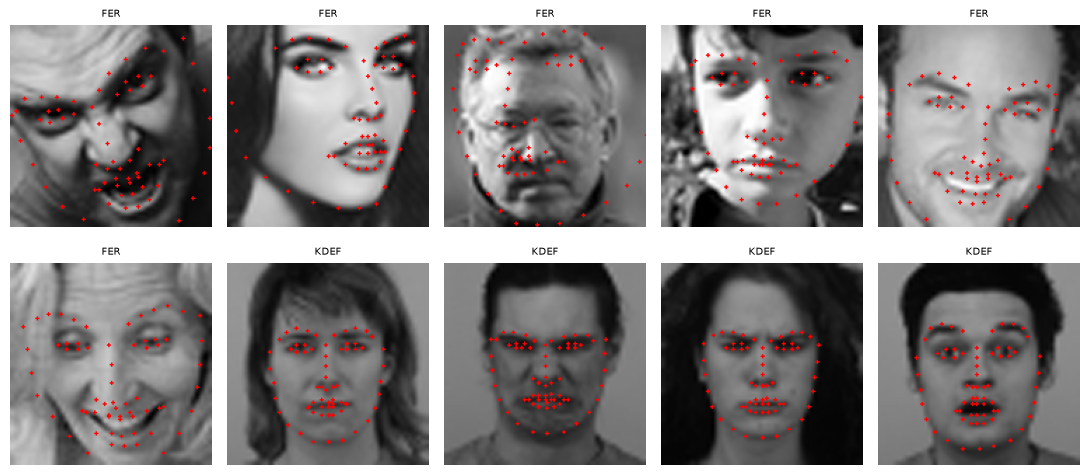

In [22]:
import cv2


def overlay(img, pts):
    big = cv2.cvtColor(cv2.resize(img, (144, 144), interpolation=cv2.INTER_CUBIC), cv2.COLOR_GRAY2RGB)
    for x, y in pts * 144:
        cv2.circle(big, (int(x), int(y)), 1, (255, 0, 0), -1)
    return big


fer_pts = np.load(F.CACHE_DIR / "fer_gray_train_pts.npy")
kd_pts = np.load(F.CACHE_DIR / "kdef_m0.2_gray_train_pts.npy")
sel_f = rng.choice(len(fer_pts), 6, replace=False)
sel_k = rng.choice(len(kd_pts), 4, replace=False)
show_images([overlay(fer["X_train"][i], fer_pts[i]) for i in sel_f] + [overlay(kd["X_train"][i], kd_pts[i]) for i in sel_k],
            ["FER"] * 6 + ["KDEF"] * 4, ncols=5, size=2.2, fname="data_landmarks.png")

### 3.6 Image variants used in the preprocessing study (Task 1/2)
*gray* (reference), *CLAHE* (local contrast equalization), *Otsu* and *adaptive* binarization
(pure black/white — "removing the greys"), *edges* (Sobel magnitude), plus RGB for KDEF.

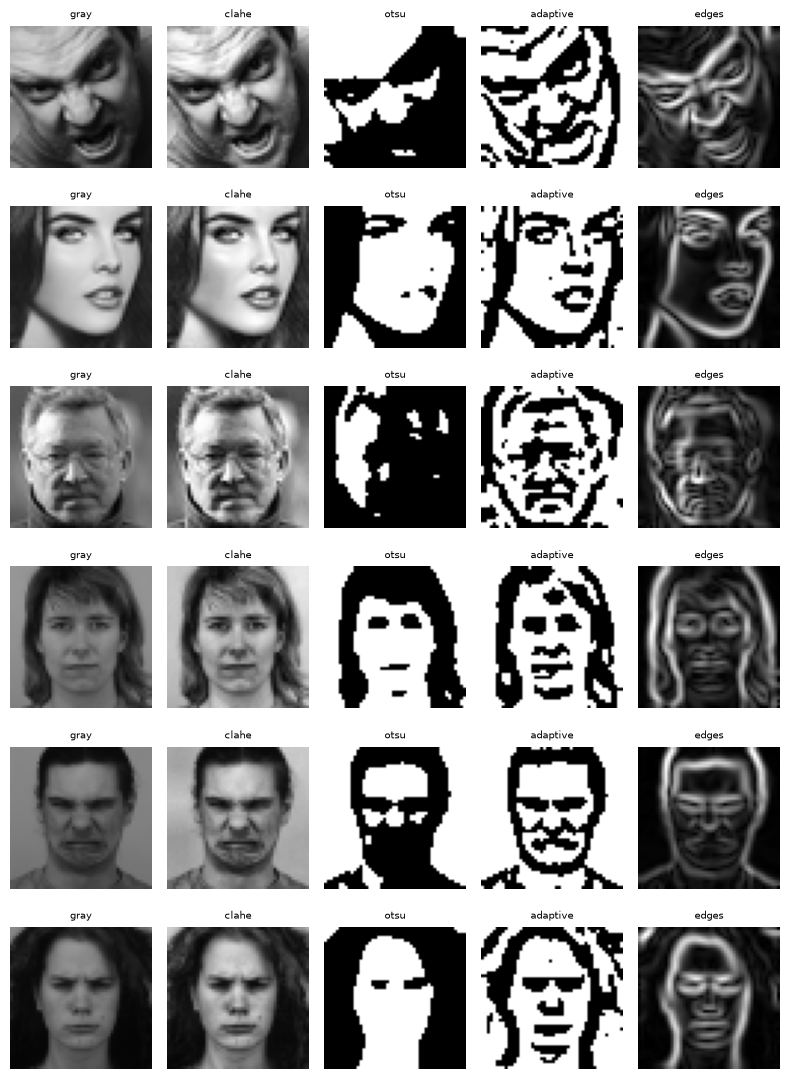

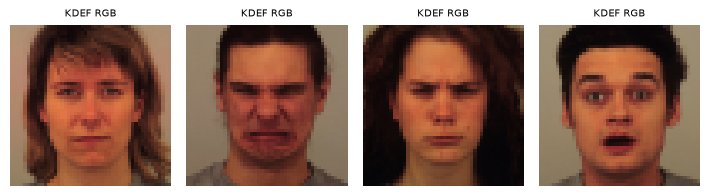

In [23]:
ex_f = fer["X_train"][sel_f[:3]]
ex_k = kd["X_train"][sel_k[:3]]
rows, titles = [], []
for im in list(ex_f) + list(ex_k):
    for v in F.VARIANTS:
        rows.append(F.apply_variant(im[None], v)[0]); titles.append(v)
show_images(rows, titles, ncols=len(F.VARIANTS), size=1.6, fname="data_variants.png")
kd_rgb = np.load(F.CACHE_DIR / "kdef_m0.2_rgb.npz")["X_train"]
show_images(list(kd_rgb[sel_k]), ["KDEF RGB"] * 4, ncols=4, size=1.8, fname="data_kdef_rgb.png")

### 3.7 Simulated FER-like degradation of KDEF (used in Tasks 3 and 5)

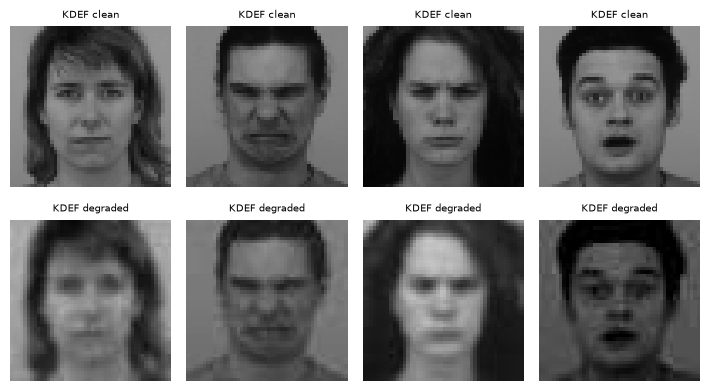

In [24]:
deg = F.degrade_batch(kd["X_train"][sel_k], seed=SEED)
show_images(list(kd["X_train"][sel_k]) + list(deg), ["KDEF clean"] * 4 + ["KDEF degraded"] * 4,
            ncols=4, size=1.8, fname="data_kdef_degraded.png")

## Summary of dataset characteristics

| | FER2013 | KDEF (frontal) |
|---|---|---|
| Size | 35,887 images (28,709 / 3,589 / 3,589) | 980 images, 70 subjects (784 / 196) |
| Acquisition | web images, in the wild | studio, posed by trained actors |
| Resolution / colour | 48×48 gray | 562×762 RGB → 48×48 gray after preprocessing |
| Classes | strongly imbalanced (Disgust ≈ 1.5 %) | perfectly balanced (140 per emotion) |
| Pose / framing | variable pose, tight crop | frontal, identical framing, crop margin is our choice |
| Lighting | very variable (see std of the per-image mean) | uniform |
| Noise | blank images, duplicates, conflicting labels, watermarks | none |
| Identity | thousands of people, no subject IDs | 70 people × 7 emotions → subject-independent split needed |

Shared challenges: 7 identical classes, subtle classes (fear vs surprise, sad vs neutral,
disgust vs angry), and person-specific facial morphology that must not be confused with expression.